# Week 7 — Wave Energy, Energy Flux & Group Velocity

**OE 754 / 854 — Ocean Waves & Tides**

Three results this week, built on the Airy solution:

$$E = \tfrac{1}{8}\rho g H^2 \quad (\text{energy density}), \qquad
\mathcal F = E\,C_g \quad (\text{energy flux}), \qquad
C_g = \frac{C}{2}\left[1 + \frac{2kh}{\sinh 2kh}\right] = nC.$$

$C_g$ is not $C$. **Wave energy propagates at the group velocity.** We'll use this for shoaling next week and for spectra in Week 13.

### Goals

1. Plot $C_g/C$ across depth regimes.
2. Draw a wave packet. The carrier moves at $C$ and the envelope at $C_g$. In deep water the carrier is twice as fast, so crests appear at the back and disappear at the front.
3. Reproduce the UNH wave tank worked example numerically.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

import figure_style as fs

g = 9.81
rho = 1025.0

## 1. $C_g/C$ across regimes

From the dispersion relation,

$$n = \frac{C_g}{C} = \frac12\left[1 + \frac{2kh}{\sinh 2kh}\right].$$

Three limits:
- **Deep**: $kh \to \infty$, $n \to 1/2$. Energy at half the phase speed.
- **Shallow**: $kh \to 0$, $n \to 1$. Energy and crests move together.
- **Intermediate**: somewhere in between.


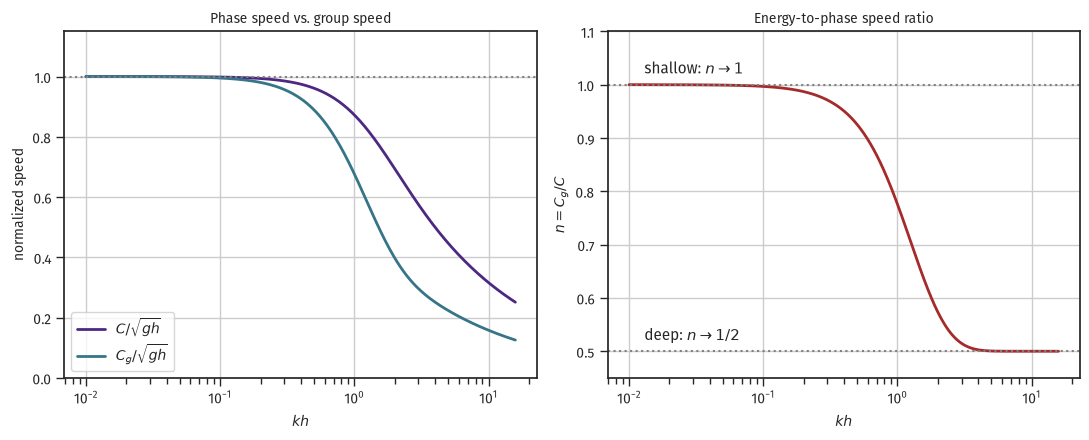

In [2]:
kh = np.logspace(-2, 1.2, 400)
n = 0.5 * (1 + 2*kh/np.sinh(2*kh))
C_over_sqrtgh = np.sqrt(np.tanh(kh) / kh)
Cg_over_sqrtgh = n * C_over_sqrtgh

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5))

ax1.semilogx(kh, C_over_sqrtgh,  lw=2, color=fs.color_list[0], label=r'$C / \sqrt{gh}$')
ax1.semilogx(kh, Cg_over_sqrtgh, lw=2, color=fs.color_list[1], label=r'$C_g / \sqrt{gh}$')
ax1.axhline(1.0, ls=':', color='0.5')
ax1.set_xlabel('$kh$')
ax1.set_ylabel('normalized speed')
ax1.set_title('Phase speed vs. group speed')
ax1.legend()
ax1.set_ylim(0, 1.15)

ax2.semilogx(kh, n, lw=2, color=fs.color_list[2])
ax2.axhline(0.5, ls=':', color='0.5')
ax2.axhline(1.0, ls=':', color='0.5')
ax2.set_xlabel(r'$kh$')
ax2.set_ylabel(r'$n = C_g / C$')
ax2.set_title(r'Energy-to-phase speed ratio')
ax2.text(0.013, 0.52, r'deep: $n \to 1/2$', fontsize=11)
ax2.text(0.013, 1.02, r'shallow: $n \to 1$', fontsize=11)
ax2.set_ylim(0.45, 1.1)

plt.tight_layout()
plt.show()

## 2. Wave packet as a still sequence

Consider two deep-water wave trains with close periods, $T_1 = 10$ and $T_2 = 10.5$ s. Let's plot their sum at a few times. The envelope (slow modulation) moves at $C_g$. The carrier (fast sinusoid) moves at $C$. In deep water $C_g = C/2$, so crests appear at the back of each packet, move forward through it, and vanish at the front.

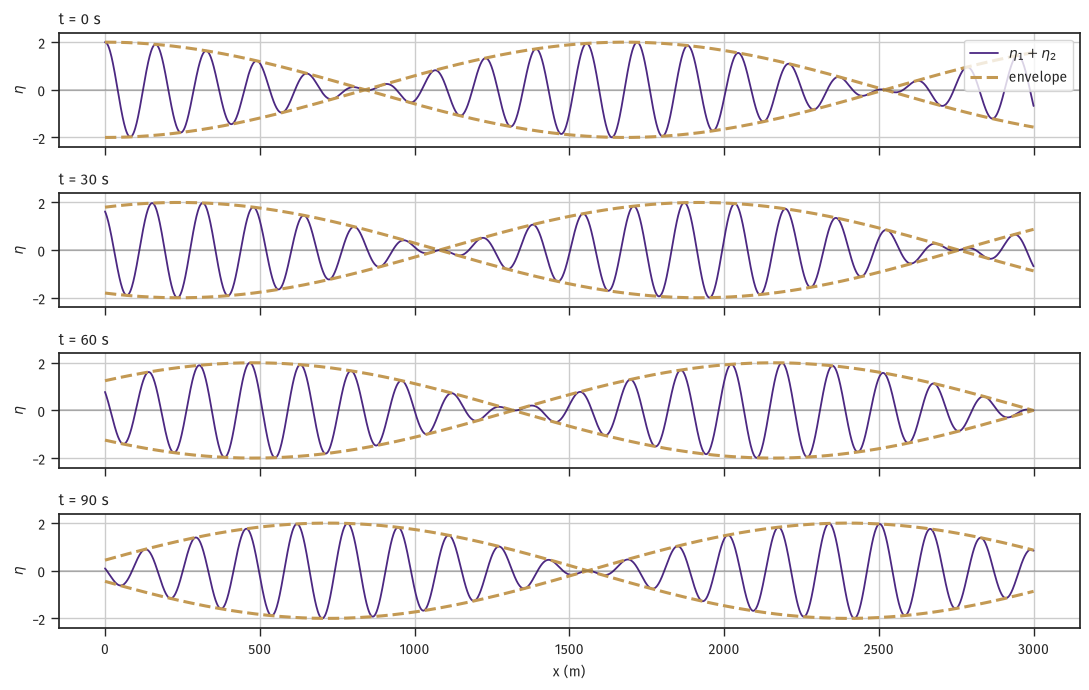

C (phase) = 15.61 m/s
C_g (group) = 8.00 m/s
C_g / C = 0.512


In [3]:
T1, T2 = 10.0, 10.5
# Deep water
omega1, omega2 = 2*np.pi/T1, 2*np.pi/T2
k1 = omega1**2 / g
k2 = omega2**2 / g
C1 = omega1/k1
C_g_mean = g / (2*(omega1+omega2)/2)  # deep-water C_g = g/(2 omega_mean), m/s

x = np.linspace(0, 3000, 2000)
fig, axes = plt.subplots(4, 1, figsize=(11, 7), sharex=True)
times = [0, 30, 60, 90]  # s

for ax, t in zip(axes, times):
    eta1 = np.cos(k1*x - omega1*t)
    eta2 = np.cos(k2*x - omega2*t)
    total = eta1 + eta2
    ax.plot(x, total, lw=1.3, color=fs.color_list[0], label='$\\eta_1 + \\eta_2$' if t==0 else None)
    # Envelope: 2 cos((dk/2) x - (domega/2) t)
    dk = (k2-k1)/2
    dom = (omega2-omega1)/2
    envelope = 2*np.cos(dk*x - dom*t)
    ax.plot(x, envelope,  ls='--', lw=2.2, color=fs.color_list[3], label='envelope' if t==0 else None)
    ax.plot(x, -envelope, ls='--', lw=2.2, color=fs.color_list[3])

    ax.set_ylim(-2.4, 2.4)
    ax.set_ylabel(r'$\eta$')
    ax.set_title(f't = {t} s', fontsize=11, loc='left')
    ax.axhline(0, color='k', lw=0.3)
    if t == 0:
        ax.legend(loc='upper right', fontsize=10)

axes[-1].set_xlabel('x (m)')
plt.tight_layout()
plt.show()

print(f'C (phase) = {C1:.2f} m/s')
print(f'C_g (group) = {C_g_mean:.2f} m/s')
print(f'C_g / C = {C_g_mean/C1:.3f}')

The envelope moves slowly to the right: $C_g = 8.00\,$m/s, so it travels 240 m in 30 s. The carrier crests move at $\approx 15.6\,$m/s, twice as fast. Follow the envelope by eye. Crests form at the trailing edge of the packet, pass through it, and disappear at the leading edge.

## 3. Energy density and flux

$E = \tfrac18 \rho g H^2$ per unit horizontal area. $\mathcal F = E \cdot C_g$ per unit crest length. Compute both for a few sea states:

In [4]:
def solve_k(omega, h, tol=1e-12):
    k = omega**2 / g
    for _ in range(50):
        tkh = np.tanh(k*h)
        f = omega**2 - g*k*tkh
        fp = -g*tkh - g*h*k*(1-tkh**2)
        dk = f/fp; k -= dk
        if abs(dk)<tol: break
    return k


print(f'{"Sea state":<20s}{"H (m)":>6s}{"T (s)":>6s}{"h (m)":>7s}'
      f'{"C (m/s)":>10s}{"C_g":>8s}{"E (kJ/m²)":>12s}{"ℱ (kW/m)":>12s}')
print('-' * 81)

scenarios = [
    ('Calm sea',        0.5, 5.0,  20.0),
    ('Moderate swell',  2.0, 10.0, 50.0),
    ('Storm',           6.0, 12.0, 30.0),
    ('Deep-water swell',4.0, 14.0, 2000.0),
    ('Tsunami (open)',  1.0, 600.0, 4000.0),
]

for name, H, T, h in scenarios:
    omega = 2*np.pi/T
    k = solve_k(omega, h)
    kh = k*h
    C = omega/k
    n = 0.5 * (1 + 2*kh/np.sinh(2*kh))
    Cg = n*C
    E = (1/8) * rho * g * H**2     # J/m^2
    F = E * Cg                     # W/m
    print(f'{name:<20s}{H:>6.1f}{T:>6.1f}{h:>7.0f}{C:>10.2f}{Cg:>8.2f}{E/1e3:>12.2f}{F/1e3:>12.2f}')

Sea state            H (m) T (s)  h (m)   C (m/s)     C_g   E (kJ/m²)    ℱ (kW/m)
---------------------------------------------------------------------------------
Calm sea               0.5   5.0     20      7.78    3.97        0.31        1.25
Moderate swell         2.0  10.0     50     15.13    8.55        5.03       43.00
Storm                  6.0  12.0     30     14.75   11.17       45.25      505.25
Deep-water swell       4.0  14.0   2000     21.86   10.93       20.11      219.79
Tsunami (open)         1.0 600.0   4000    196.61  193.70        1.26      243.46


Some scales:

- A moderate 2-m, 10-s swell carries **43 kW per meter of crest** in 50 m of water. Average household power draw is about 1 kW. So a meter of this crest could run about 40 houses at 100% capture efficiency. Hence the interest in wave energy conversion.
- A 6-m storm wave is **9× more energetic** per unit area than the 2-m swell (45.25 vs. 5.03 kJ/m²). This is the $H^2$ dependence: $(6/2)^2 = 9$.
- The tsunami's energy density is modest: 1.26 kJ/m², a quarter of the moderate swell's. But its group speed is 194 m/s, so the flux is **243 kW/m**. That is above the 4-m deep-water swell's 220 kW/m. Multiply by a 400-km crest and you get about 100 GW. Energy density and energy flux are different quantities. For shallow-water-limit waves they can differ greatly.

## 4. UNH wave tank worked example

From the lecture notes: 1 kW power input to a 3-m-wide tank with 2-m water depth, wavemaker driving at $T = 1.5\,$s. What is the steady-state wave height?

Power in = energy flux out, so $1\,\text{kW} = E\,C_g \cdot W$ ($W = 3\,$m, the tank width). Solve for $H$:

In [5]:
T = 1.5
h = 2.0
W = 3.0            # tank width, m
P_in = 1000.0      # power input, W

omega = 2*np.pi/T
k_tank = solve_k(omega, h)
kh = k_tank*h
C = omega/k_tank
n = 0.5*(1 + 2*kh/np.sinh(2*kh))
Cg = n*C
L = 2*np.pi/k_tank

print(f'T = {T} s, h = {h} m:')
print(f'  L  = {L:.3f} m')
print(f'  kh = {kh:.3f}   regime: {"deep" if kh>np.pi else "intermediate"}')
print(f'  C  = {C:.3f} m/s,  C_g = {Cg:.3f} m/s,  n = {n:.3f}')
print()

# E Cg W = P_in  ->  (rho g/8) H^2 Cg W = P_in
H_sq = 8 * P_in / (rho * g * Cg * W)
H_ideal = np.sqrt(H_sq)
print(f'Ideal wave height:  H = {H_ideal:.3f} m')
print(f'Wave steepness:    H/L = {H_ideal/L:.3f}   (breaking limit 1/7 = 0.143)')

# Real wavemakers run 30-60% efficient
for eta_eff in [0.30, 0.50, 0.60]:
    H_real = np.sqrt(8 * eta_eff * P_in / (rho * g * Cg * W))
    print(f'  at {int(eta_eff*100)}% efficiency:  H = {H_real:.3f} m')

T = 1.5 s, h = 2.0 m:
  L  = 3.508 m
  kh = 3.583   regime: deep
  C  = 2.338 m/s,  C_g = 1.182 m/s,  n = 0.506

Ideal wave height:  H = 0.474 m
Wave steepness:    H/L = 0.135   (breaking limit 1/7 = 0.143)
  at 30% efficiency:  H = 0.259 m
  at 50% efficiency:  H = 0.335 m
  at 60% efficiency:  H = 0.367 m


$H \approx 0.48\,$m ideal, so $H/L \approx 0.14$. That is a very steep wave, right at the breaking limit. It takes a large power input to drive a moderately sized wave. From the scaling $H \propto \sqrt{P}$, a 20 cm wave needs about 170 W.

At realistic paddle efficiencies (30–60%) the largest achievable wave is about 0.3 m. That is still steep, but more useful for model testing.

## 5. Exercise: $C$ and $C_g$ at one site

A NOAA buoy site has water depth $h = 25\,$m. Three swells arrive with $T = 6, 10, 16\,$s. For each, compute $L$, $C$, $C_g$, and classify the regime. The longer swells sit closer to shallow-water behavior at this depth, with a larger $C_g/C$. Why?

**Warm-up for PS4.** Take the $T = 10$ s swell with $H = 1$ m in $h = 25$ m (you just computed its $C_g$). Shoal it to $h = 8$ m using energy-flux conservation: $H_2 = H_1\sqrt{C_{g1}/C_{g2}}$ (normal incidence, no refraction yet). The Week 8 notebook adds refraction.

## Looking ahead

Week 8 uses energy-flux conservation ($E C_g$ constant along a ray) and Snell's law ($k\sin\theta$ constant across parallel contours). These give the shoaling and refraction coefficients. PS4 Problem 1 asks you to apply them.